In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, root_scalar, minimize_scalar

#archivo
nombre_archivo='TIAcianinas_datos_correctos.xlsx'

# Cargar el archivo Excel
datos = pd.read_excel(nombre_archivo)
print(datos.columns.tolist())

# La primera columna es la longitud de onda
onda_col = datos.columns[0]
# Las demás columnas son las muestras
muestras = datos.columns[1:]

['Wavelength_nm', 'DTTC', 'DTDC', 'DTCI']


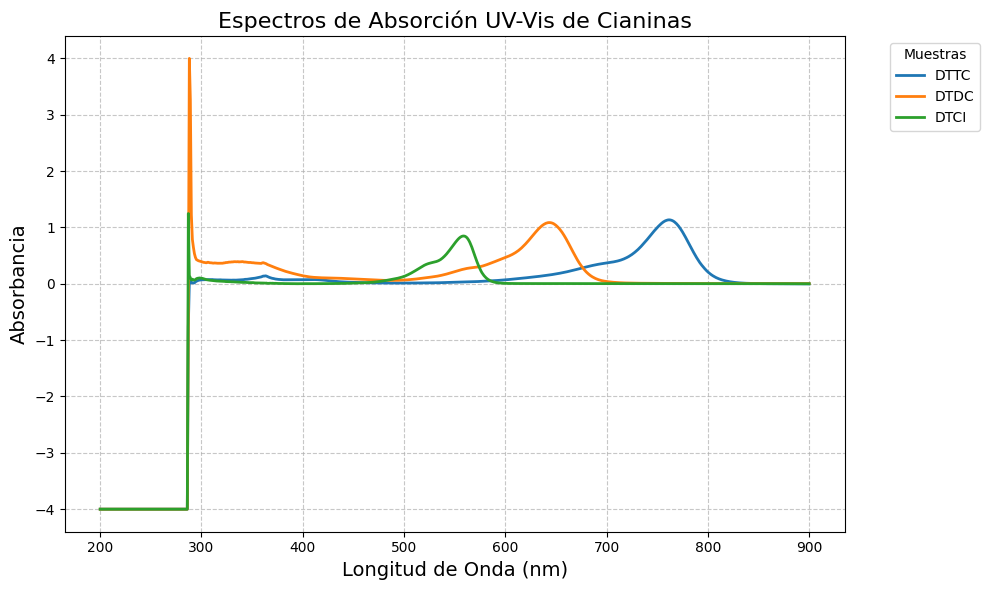

In [4]:
# BLOQUE 2: Gráfico de Espectros UV-Vis
plt.figure(figsize=(10, 6))

# Iterar sobre todas las columnas y graficarlas
for muestra in muestras:
    plt.plot(datos[onda_col], datos[muestra], label=muestra, linewidth=2)

# Formato del gráfico
plt.title('Espectros de Absorción UV-Vis de Cianinas', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend(title='Muestras', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

In [5]:
#Datos limpios (los máximos, es lo mismo que hice antes)
lambdas_max = {}

print("Resultados experimentales (Picos máximos de absorción):")
print("-" * 50)
datos_1 = datos[(datos['Wavelength_nm'] >= 300)]
for muestra in muestras:
    # Encontrar el índice donde la absorbancia es máxima
    indice_max = datos_1[muestra].idxmax() #encuentra el maximo valor y nos da el lugar
    # Encontrar la longitud de onda en ese índice
    l_max = datos_1[onda_col].loc[indice_max]
    absorbancia_max = datos_1[muestra].loc[indice_max]

    # Guardar los datos extraídos para el gráfico final
    lambdas_max[muestra] = l_max
    print(f"{muestra}: Lambda_max = {l_max} nm (Absorbancia: {absorbancia_max:.3f})")


Resultados experimentales (Picos máximos de absorción):
--------------------------------------------------
DTTC: Lambda_max = 762 nm (Absorbancia: 1.134)
DTDC: Lambda_max = 643 nm (Absorbancia: 1.086)
DTCI: Lambda_max = 559 nm (Absorbancia: 0.848)


--------------------------------------------------
AJUSTE COMPLETADO EXITOSAMENTE
Profundidad del pozo de potencial óptima: V0 = 7.80 eV
--------------------------------------------------


<>:109: SyntaxWarning: invalid escape sequence '\l'
<>:109: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1136/576095415.py:109: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('Longitud de onda de máxima absorción $\lambda_{max}$ (nm)', fontsize=12)


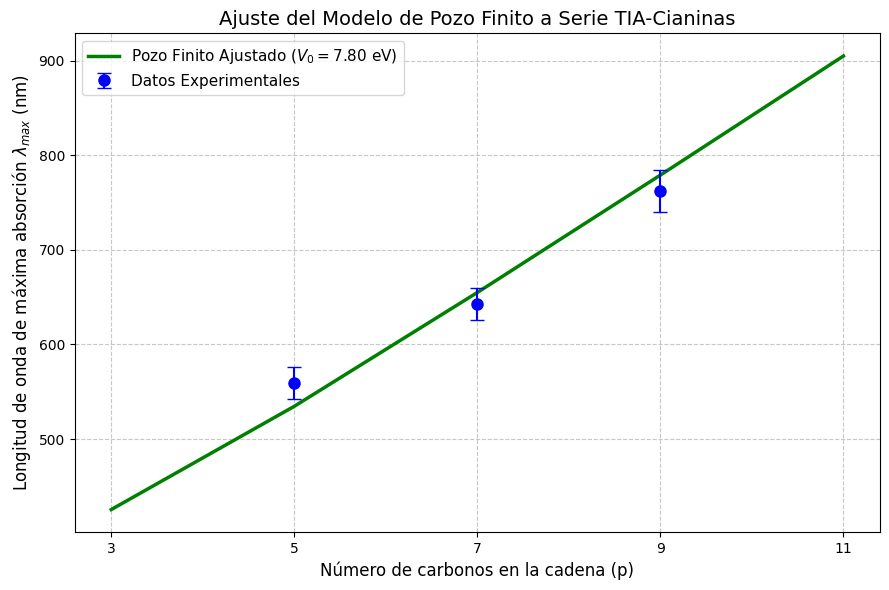

In [6]:
#datos experimentales
p_exp = np.array([5,7,9])
lambda_exp = np.array([559,643,762])
sigma_exp = np.array([17,17,22])

#defino constantes y las funciones solución pares e impares
h = 6.62607015e-34     # Constante de Planck (J*s)
hbar = h / (2 * np.pi) # Constante reducida (J*s)
m = 9.10938356e-31     # Masa del electrón (kg)
c = 299792458          # Velocidad de la luz (m/s)
e_charge = 1.602e-19   # Conversión de eV a Joules
d = 0.14e-9            # Distancia de enlace (m)


def funcion_par(v, u0_val):
    adentro = max(0.0, u0_val**2 - v**2)
    return v * np.tan(v) - np.sqrt(adentro)

def funcion_impar(v, u0_val):
    adentro = max(0.0, u0_val**2 - v**2)
    return -v / np.tan(v) - np.sqrt(adentro)

def encontrar_interseccion(n, u0_val):
    # La solución para el nivel n está entre (n-1)*pi/2 y n*pi/2
    limite_inf = (n - 1) * np.pi / 2 + 1e-5
    limite_sup = n * np.pi / 2 - 1e-5

    if u0_val <= limite_inf:
        return None

    if limite_sup > u0_val:
        limite_sup = u0_val - 1e-5

    # Determinar qué ecuación usar (par o impar)
    if n % 2 != 0:
        func = lambda v: funcion_par(v, u0_val)
    else:
        func = lambda v: funcion_impar(v, u0_val)

    try:
        sol = root_scalar(func, bracket=[limite_inf, limite_sup], method='brentq')
        return sol.root
    except ValueError:
        return None

# =========================================================
# 4. CALCULAR LONGITUD DE ONDA TEÓRICA
# =========================================================
def calcular_lambda_modelo(p, V0_eV):
    a = (p + 2) * d
    V0_J = V0_eV * e_charge
    u0 = (a / 2) * np.sqrt(2 * m * V0_J) / hbar

    # Niveles de energía inicial y final
    n_homo = int((p + 3) / 2)
    n_lumo = n_homo + 1 #hay que chequear esto

    # Encontrar cruces v para ambos niveles
    v_homo = encontrar_interseccion(n_homo, u0)
    v_lumo = encontrar_interseccion(n_lumo, u0)

    # Si el pozo es tan poco profundo que no retiene el LUMO, devolvemos un error alto
    if v_homo is None or v_lumo is None:
        return 1e6

    # Calcular energías reales
    E_homo = (2 * hbar**2 * v_homo**2) / (m * a**2)
    E_lumo = (2 * hbar**2 * v_lumo**2) / (m * a**2)

    dE = E_lumo - E_homo
    return (h * c / dE) * 1e9

# =========================================================
# 5. RUTINA DE OPTIMIZACIÓN (AJUSTE)
# =========================================================
def funcion_error(V0_eV):
    error_cuadratico = 0
    for i in range(len(p_exp)):
        l_teorica = calcular_lambda_modelo(p_exp[i], V0_eV)
        error_cuadratico += (l_teorica - lambda_exp[i])**2
    return error_cuadratico

# Buscamos el mejor V0 en un rango lógico para moléculas orgánicas (8 a 15 eV)
resultado = minimize_scalar(funcion_error, bounds=(5, 15), method='bounded')
V0_optimo = resultado.x

print("-" * 50)
print(f"AJUSTE COMPLETADO EXITOSAMENTE")
print(f"Profundidad del pozo de potencial óptima: V0 = {V0_optimo:.2f} eV")
print("-" * 50)

# =========================================================
# 6. GRÁFICO FINAL
# =========================================================
# Usamos solo valores enteros impares para evitar distorsiones matemáticas
p_enteros = np.array([3, 5, 7, 9, 11])
lambda_ajustados = [calcular_lambda_modelo(p, V0_optimo) for p in p_enteros]

plt.figure(figsize=(9, 6))

# Curva teórica ajustada
plt.plot(p_enteros, lambda_ajustados, 'g-', linewidth=2.5, label=f'Pozo Finito Ajustado ($V_0 = {V0_optimo:.2f}$ eV)')

# Puntos experimentales con error
plt.errorbar(p_exp, lambda_exp, yerr=sigma_exp, fmt='bo', markersize=8, capsize=5, label="Datos Experimentales")

plt.title('Ajuste del Modelo de Pozo Finito a Serie TIA-Cianinas', fontsize=14)
plt.xlabel('Número de carbonos en la cadena (p)', fontsize=12)
plt.ylabel('Longitud de onda de máxima absorción $\lambda_{max}$ (nm)', fontsize=12)
plt.xticks(p_enteros)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()